# Занятие 7. Численные методы решения уравнения диффузии
## Дискретные гармоники → устойчивость ОДУ → спектр диффузии → численные схемы

**Сюжет:** почему одни схемы требуют малого шага времени, а другие устойчивы при любом шаге,
но могут неправильно воспроизводить затухание?

Это дополнительный, самостоятельный вариант лекции на **90 минут**. Исходный ноутбук
[о теплопроводности](lesson_07_heat.ipynb) сохранён отдельно.

| Время | Блок | Демонстрация |
|---|---|---|
| 0–12 | Дискретные гармоники | Базис, Найквист, чётные/нечётные сетки, алиасинг |
| 12–27 | Абсолютная, A- и L-устойчивость | Комплексная плоскость и тестовое ОДУ |
| 27–37 | Диффузия и её спектр | Точное затухание полудискретных мод |
| 37–52 | Явный Эйлер (FTCS) | r = 0.25, 0.5, 0.6 |
| 52–65 | Неявный Эйлер | Устойчивость большого шага и его ошибка |
| 65–78 | Кранк–Николсон | Порядок, осцилляции, старт Раннахера |
| 78–85 | Границы и баланс | Изоляция, термостаты, теплообмен |
| 85–90 | Сравнение | Точность, шаг, стоимость, домашняя работа |

Все кодовые ячейки готовы к запуску. **Kernel → Restart Kernel and Run All** воспроизводит
графики без действий с виджетами. В каждом интерактивном блоке измените параметры и нажмите
**«Обновить»**. Рядом оставлен обычный вызов функции, работающий без `ipywidgets`.
Сохранённые графики доступны и без запуска ядра; работа виджетов требует Python-ядра.

Зависимости: NumPy, SciPy, Matplotlib, IPython; необязательно ipywidgets.
Код расчётных функций включён внутрь ноутбука, поэтому файл можно переносить отдельно.

## Блок 0. Подготовка
Обозначения: $L=1$, $h=L/N$, шаг времени $\tau$, температуропроводность $\kappa$,
диффузионное число $r=\kappa\tau/h^2$. Все величины безразмерные.
EE — явный Эйлер, IE — неявный Эйлер, CN — Кранк–Николсон.

В блоках 1–6 и 8 сетка периодическая, без повторения правого конца.
В блоке 7 используется отдельная сетка центров ячеек для консервативного учёта границ.
Большую следующую ячейку удобно свернуть после запуска: это библиотека готовых функций.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10,4), 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': .22,
                     'animation.embed_limit': 20})

In [2]:
"""Расчётные функции альтернативной лекции. Код также включается внутрь ноутбука."""
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye
from scipy.sparse.linalg import splu
from scipy.linalg import eigh
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

METHODS = {'EE': 0., 'IE': 1., 'CN': .5}
COLORS = {'EE': '#2878b5', 'IE': '#d47d17', 'CN': '#248267'}
LABELS = {'EE': 'Явный Эйлер', 'IE': 'Неявный Эйлер', 'CN': 'Кранк–Николсон'}


def amplification(z, method):
    """R(z), z = tau * lambda; полюса возвращают inf/nan."""
    z = np.asarray(z, dtype=complex)
    theta = METHODS[method]
    with np.errstate(divide='ignore', invalid='ignore'):
        return (1+(1-theta)*z)/(1-theta*z)


def grid_spectrum(N=64, kappa=1.):
    h = 1/N
    x = np.arange(N)*h  # x=1 не дублируется
    m = np.arange(N)
    lam = -4*kappa/h**2*np.sin(np.pi*m/N)**2
    return x, h, lam


def periodic_matrix(N=64, kappa=1.):
    """Циклическая трёхдиагональная матрица: есть два угловых элемента."""
    a = kappa*N*N
    A = diags([np.full(N-1,a), np.full(N,-2*a), np.full(N-1,a)],
              [-1,0,1], format='lil')
    A[0,-1] = A[-1,0] = a
    return A.tocsc()


def profile(x, kind='smooth'):
    # Гладкий периодический аналог гауссова импульса: все производные на концах согласованы.
    if kind == 'smooth':
        return np.exp(-8*(1-np.cos(2*np.pi*(x-.5))))
    if kind == 'box':
        return ((x >= .375) & (x < .625)).astype(float)
    raise ValueError(kind)


def semidiscrete_exact(u0, times, kappa=1.):
    """Точный эталон системы U'=A U, а не непрерывного уравнения."""
    lam = grid_spectrum(len(u0), kappa)[2]
    return np.fft.ifft(np.exp(np.outer(np.asarray(times),lam))*np.fft.fft(u0), axis=1).real


def periodic_solve(u0, T, tau, method, kappa=1., unsafe=False, rannacher=False):
    """Равномерные шаги до одного T; фактический tau <= запрошенного.

    Сохраняется каждый слой. Неявные методы решают циклическую систему,
    FFT используется только для независимого эталона.
    """
    N = len(u0)
    if T <= 0 or tau <= 0 or kappa <= 0:
        raise ValueError('T, tau, kappa должны быть положительными')
    steps = int(np.ceil(T/tau-1e-12))
    if steps > 100000:
        raise ValueError('Слишком много шагов для лекционной демонстрации')
    tau = T/steps
    r = kappa*tau*N*N
    if method == 'EE' and r > .5+1e-12 and not unsafe:
        raise ValueError(f'Для EE нарушено r <= 1/2: r={r:g}')
    if rannacher and method != 'CN':
        raise ValueError('Сглаживающий старт предусмотрен для CN')
    A = periodic_matrix(N,kappa)
    I = eye(N, format='csc')
    theta = METHODS[method]
    B = I+(1-theta)*tau*A
    solver = splu(I-theta*tau*A).solve if theta else None
    U = np.empty((steps+1,N)); U[0] = u0
    for n in range(steps):
        if n == 0 and rannacher:
            half = splu(I-.5*tau*A).solve
            U[n+1] = half(half(U[n]))
        else:
            rhs = B @ U[n]
            U[n+1] = solver(rhs) if solver else rhs
        if not np.isfinite(U[n+1]).all() or np.max(abs(U[n+1])) > 1e100:
            raise FloatingPointError(f'Чрезмерный рост при t={(n+1)*tau:g}')
    times = np.linspace(0,T,steps+1)
    mean = U.mean(axis=1)
    return dict(t=times,u=U,tau=tau,r=r,steps=steps,
                heat=mean,maximum=np.max(abs(U),axis=1),
                l2=np.sqrt(np.mean((U-mean[:,None])**2,axis=1)))


def panel(fn, **controls):
    """Общий интерфейс: изменить параметры и нажать «Обновить».

    Без ipywidgets используются обычные вызовы функций, уже присутствующие ниже.
    """
    try:
        import ipywidgets as w
    except ImportError:
        print('Виджеты не установлены. Измените параметры обычного вызова в следующей ячейке.')
        return
    widget = w.interactive(fn, {'manual': True, 'manual_name': 'Обновить'}, **controls)
    display(widget)


def experiment1(N=32, m=1, parts='Обе части'):
    x = np.arange(N)/N
    m = int(m)  # допускаются номера вне основного диапазона: это алиасы
    xx = np.linspace(0,1,max(1200,40*(abs(m)+N)))
    fig, ax = plt.subplots(1,2,figsize=(13,3.6))
    for part,color,label in [(np.cos,'#2878b5','Re: cos'),(np.sin,'#d47d17','Im: sin')]:
        if parts == 'Только Re' and part is np.sin: continue
        if parts == 'Только Im' and part is np.cos: continue
        ax[0].plot(xx,part(2*np.pi*m*xx),color=color,alpha=.45)
        ax[0].plot(x,part(2*np.pi*m*x),'o',color=color,label=label,ms=4)
    ax[1].plot(xx,np.cos(2*np.pi*m*xx),label=f'm = {m}',lw=2)
    ax[1].plot(xx,np.cos(2*np.pi*(m+N)*xx),alpha=.45,label=f'm + N = {m+N}')
    ax[1].plot(x,np.cos(2*np.pi*m*x),'ko',ms=4,label='Совпадающие отсчёты')
    for a in ax:
        a.set(xlim=(0,1),ylim=(-1.2,1.2),xlabel='x',ylabel='Значение');a.legend(fontsize=9)
    ax[0].set_title(f'N={N}, m={m}, θ=2π·{m}/{N}')
    ax[1].set_title('Алиасинг: различие только между узлами')
    fig.tight_layout();plt.show()
    alias_error = np.max(abs(np.exp(2j*np.pi*m*x)-np.exp(2j*np.pi*(m+N)*x)))
    print(f'Ошибка совпадения в узлах: {alias_error:.2e}. ' +
          ('На сетке есть мода Найквиста m=N/2.' if N%2==0 else 'N нечётно: отдельной моды Найквиста нет.'))


def experiment2(real=-3., imag=0.):
    z = complex(real,imag)
    re,im = np.meshgrid(np.linspace(-5,3,400),np.linspace(-4,4,400))
    Z = re+1j*im
    fig,axes = plt.subplots(2,3,figsize=(14,7))
    tt=np.linspace(0,12,600);nn=np.arange(13)
    for col,method in enumerate(METHODS):
        R=amplification(Z,method)
        axes[0,col].contourf(re,im,(abs(R)<=1).astype(int),levels=[-.5,.5,1.5],colors=['#f7f7f7','#c6e2d8'])
        axes[0,col].contour(re,im,abs(R),levels=[1],colors=['#248267'])
        axes[0,col].plot(z.real,z.imag,'ro');axes[0,col].axvline(0,color='grey',lw=.6)
        axes[0,col].axhline(0,color='grey',lw=.6)
        axes[0,col].set(xlabel='Re z',ylabel='Im z',title=LABELS[method],aspect='equal')
        r=complex(amplification(z,method))
        if not np.isfinite(r):
            axes[1,col].text(.1,.5,'Полюс R(z): шаг не определён',transform=axes[1,col].transAxes)
            continue
        yy=r**nn
        axes[1,col].plot(tt,np.exp(z*tt).real,'k--',label='Re точного')
        axes[1,col].plot(nn,yy.real,'o-',color=COLORS[method],label='Re численного')
        if abs(z.imag)>1e-12:
            axes[1,col].plot(tt,np.exp(z*tt).imag,':',color='grey',label='Im точного')
            axes[1,col].plot(nn,yy.imag,'s:',color=COLORS[method],label='Im численного')
        # Общий симметричный логарифмический масштаб: рост EE не прячет остальные методы.
        axes[1,col].set_yscale('symlog',linthresh=1)
        axes[1,col].set(ylim=(-1e12,1e12),xlabel='t / τ = n',ylabel='y, symlog',title=f'R={r:.3g}, |R|={abs(r):.3g}')
        axes[1,col].set_yticks([-1e12,-1e6,-1,0,1,1e6,1e12])
        axes[1,col].minorticks_off()
        axes[1,col].legend(fontsize=8)
    fig.tight_layout();plt.show()
    print('Начальное значение y₀=1; τ=1, λ=z. Зелёный фон: |R(z)|≤1. Для Re z>0 точное решение тоже растёт.')


def experiment3(a=10.):
    aa=np.linspace(0,40,500)
    fig,ax=plt.subplots(1,2,figsize=(12,3.8))
    ax[0].plot(aa,np.exp(-aa),'k--',label='exp(−a)')
    for method in ['IE','CN']:
        ax[0].plot(aa,amplification(-aa,method).real,label=LABELS[method],color=COLORS[method])
    ax[0].axhline(0,color='grey',lw=.6);ax[0].axvline(a,color='grey',ls=':')
    ax[0].set(xlabel='a = μτ',ylabel='Множитель за шаг',ylim=(-1.1,1.1));ax[0].legend()
    n=np.arange(11)
    ax[1].plot(n,np.exp(-a*n),'k--',label='Точное')
    for method in ['IE','CN']:
        ax[1].plot(n,amplification(-a,method).real**n,'o-',label=method,color=COLORS[method])
    ax[1].set(xlabel='Номер шага',ylabel='yₙ',ylim=(-1.1,1.1),title=f'a={a:g}');ax[1].legend()
    fig.tight_layout();plt.show()


def experiment4(N=64, kappa=1.):
    x,h,lam=grid_spectrum(N,kappa)
    modes=[1,N//8,N//2]
    T=.02/kappa;times=np.linspace(0,T,200)
    fig,ax=plt.subplots(1,3,figsize=(14,3.8))
    m=np.arange(N)
    ax[0].plot(m,lam,'o',ms=3);ax[0].set(xlabel='Номер m в DFT',ylabel='λₘ',title='Спектр периодического оператора')
    for mode in modes:
        ax[1].semilogy(times,np.exp(lam[mode]*times),label=f'm={mode}')
    ax[1].set(ylim=(1e-12,1.1),xlabel='Время',ylabel='Амплитуда');ax[1].legend()
    initial=.3+sum(np.cos(2*np.pi*mode*x)/3 for mode in modes)
    for t,u in zip([0,.1*h*h/kappa,h*h/kappa,T],semidiscrete_exact(initial,[0,.1*h*h/kappa,h*h/kappa,T],kappa)):
        ax[2].plot(x,u,label=f't={t:.3g}')
    ax[2].set(xlabel='x',ylabel='Температура',ylim=(-.8,1.5));ax[2].legend(fontsize=8)
    fig.tight_layout();plt.show()
    print(f'h={h:g}; max |λ|={max(abs(lam)):.4g}; мода m=0 не затухает.')
    print('m>N/2 соответствует отрицательным частотам m−N; частота не растёт монотонно с индексом DFT.')


def experiment5(N=64):
    x,h,lam=grid_spectrum(N)
    u0=profile(x)+1e-5*(-1.)**np.arange(N)
    T=30*h*h  # для r=.25,.5,.6 получается целое число шагов
    fig,ax=plt.subplots(1,3,figsize=(14,3.8))
    runs={}
    for r in [.25,.5,.6]:
        res=periodic_solve(u0,T,r*h*h,'EE',unsafe=r>.5);runs[r]=res
        ax[0].plot(x,res['u'][-1],label=f'r={r}')
        ax[1].semilogy(res['t'],res['maximum'],label=f'r={r}')
        ax[2].semilogy(res['t'],res['l2'],label=f'r={r}')
    exact=semidiscrete_exact(u0,[T])[0]
    ax[0].plot(x,exact,'k--',label='Эталон')
    ax[0].set(xlabel='x',ylabel='U',title=f'Общее время T={T:.4g}')
    ax[1].set(xlabel='Время',ylabel='max |U|')
    ax[2].set(xlabel='Время',ylabel='‖U − среднее‖₂,h')
    for a in ax:a.legend(fontsize=8)
    fig.tight_layout();plt.show()
    fig,ax=plt.subplots(figsize=(8,2.8))
    for n in [0,1,2]:
        ax.plot(x[:12],(-1.)**(np.arange(N)+n)[:12],'o-',label=f'Слой n={n}',alpha=.65)
    ax.set(xlabel='x (фрагмент сетки)',ylabel='Мода Найквиста',ylim=(-1.2,1.2),title='r=1/2: G(π)=−1, затухания нет');ax.legend()
    fig.tight_layout();plt.show()
    print('Максимумы при общем T:',{r:float(res['maximum'][-1]) for r,res in runs.items()})
    return runs


def experiment6(N=64):
    x,h,_=grid_spectrum(N);u0=profile(x);T=.01
    exact=semidiscrete_exact(u0,[T])[0]
    configs=[('EE',.4*h*h),('IE',.4*h*h),('IE',T/10),('IE',T)]
    fig,ax=plt.subplots(1,2,figsize=(12,3.8))
    ax[0].plot(x,exact,'k--',lw=2,label='Полудискретный эталон')
    for method,tau in configs:
        res=periodic_solve(u0,T,tau,method)
        label=f'{method}: {res["steps"]} шаг., r={res["r"]:.2g}'
        ax[0].plot(x,res['u'][-1],label=label)
        ax[1].plot(x,res['u'][-1]-exact,label=label)
        print(f'{label}; E∞={max(abs(res["u"][-1]-exact)):.4e}')
    ax[0].set(xlabel='x',ylabel='Температура',ylim=(-.05,1.05));ax[0].legend(fontsize=8)
    ax[1].set(xlabel='x',ylabel='Ошибка при T=0.01');ax[1].legend(fontsize=8)
    fig.tight_layout();plt.show()


def convergence_data(N=64):
    x,h,_=grid_spectrum(N);u0=profile(x);T=.02
    # Все методы сравниваются на одних шагах, но неустойчивый EE не запускается.
    steps_list=[8,16,32,64,128,256,512]
    exact=semidiscrete_exact(u0,[T])[0]
    records=[]
    for steps in steps_list:
        tau=T/steps;r=tau/h**2
        for method in METHODS:
            if method=='EE' and r>.5:
                records.append((method,tau,r,steps,np.nan,np.nan))
                continue
            res=periodic_solve(u0,T,tau,method)
            err=max(abs(res['u'][-1]-exact))
            drift=max(abs(res['heat']-res['heat'][0]))
            records.append((method,tau,r,steps,err,drift))
    return records


def experiment7(N=128, r=20.):
    x,h,_=grid_spectrum(N);u0=profile(x,'box');tau=r*h*h;T=4*tau
    refs=semidiscrete_exact(u0,[tau,T])
    fig,ax=plt.subplots(1,2,figsize=(12,3.8))
    for method,start,label in [('IE',False,'IE'),('CN',False,'CN'),('CN',True,'CN + Раннахер')]:
        res=periodic_solve(u0,T,tau,method,rannacher=start)
        for a,index,ref in zip(ax,[1,4],refs):a.plot(x,res['u'][index],label=label)
    for a,t,ref in zip(ax,[tau,T],refs):
        a.plot(x,ref,'k--',label='Эталон');a.set(xlim=(.25,.75),ylim=(-.25,1.25),xlabel='x',ylabel='U',title=f't={t:.4g}');a.legend(fontsize=9)
    fig.tight_layout();plt.show()
    records=convergence_data(64)
    fig,ax=plt.subplots(figsize=(7,3.5))
    for method in ['IE','CN']:
        data=[row for row in records if row[0]==method]
        ax.loglog([v[1] for v in data],[v[4] for v in data],'o-',label=method,color=COLORS[method])
        print(method,'временной порядок по двум самым мелким шагам:',np.log2(data[-2][4]/data[-1][4]))
    ax.set(xlabel='τ',ylabel='E∞ относительно exp(tA)U₀',title='Гладкий периодический импульс, N=64, T=0.02');ax.legend()
    fig.tight_layout();plt.show()


def boundary_problem(kind,N=80,kappa=.2,transfer=2.,T=8.,tau=.02):
    """Конечные объёмы, c_v=1. Робин: сопротивление h/(2κ)+1/α."""
    h=1/N;x=(np.arange(N)+.5)*h
    interior=np.full(N-1,kappa/h)
    if kind=='Нейман':
        cL=cR=0.;TL=TR=0.;equilibrium=np.full(N,(1+.5*np.sin(np.pi*x)).mean())
    elif kind=='Дирихле':
        cL=cR=2*kappa/h;TL=1.;TR=0.;equilibrium=1-x
    elif kind=='Робин':
        cL=cR=1/(h/(2*kappa)+1/transfer);TL=TR=0.;equilibrium=np.zeros(N)
    else:raise ValueError(kind)
    face=np.r_[cL,interior,cR]
    A=diags([interior/h,-(face[:-1]+face[1:])/h,interior/h],[-1,0,1],format='csc')
    b=np.zeros(N);b[0]=cL*TL/h;b[-1]=cR*TR/h
    u0=1+.5*np.sin(np.pi*x)
    steps=int(np.ceil(T/tau));tau=T/steps;times=np.linspace(0,T,steps+1)
    solve=splu(eye(N,format='csc')-tau*A).solve
    U=np.empty((steps+1,N));U[0]=u0;integral=np.zeros(steps+1)
    for n in range(steps):
        U[n+1]=solve(U[n]+tau*b)
        qL=cL*(TL-U[n+1,0]);qR=cR*(U[n+1,-1]-TR)
        integral[n+1]=integral[n]+tau*(qL-qR)
    heat=h*U.sum(axis=1)
    values,vectors=eigh(A.toarray())
    # Независимый от шага времени эталон той же пространственной системы.
    reference=equilibrium+vectors@(np.exp(values*T)*(vectors.T@(u0-equilibrium)))
    return dict(x=x,t=times,u=U,heat=heat,balance=heat-heat[0]-integral,
                integral=integral,equilibrium=equilibrium,reference=reference)


def experiment8(transfer=2.):
    fig,ax=plt.subplots(1,3,figsize=(14,3.8))
    data={}
    for a,kind in zip(ax,['Нейман','Дирихле','Робин']):
        res=boundary_problem(kind,transfer=transfer);data[kind]=res
        for t in [0,.2,1,8]:
            i=np.argmin(abs(res['t']-t));a.plot(res['x'],res['u'][i],label=f't={res["t"][i]:g}')
        a.plot(res['x'],res['equilibrium'],'k--',label='Стационар')
        a.plot(res['x'],res['reference'],'k:',label='Эталон при T')
        a.set(xlabel='x',ylabel='u',ylim=(-.05,1.6),title=kind);a.legend(fontsize=8)
        print(kind,'невязка баланса:',max(abs(res['balance'])),
              'ошибка при T:',max(abs(res['u'][-1]-res['reference'])))
    fig.tight_layout();plt.show()
    fig,ax=plt.subplots(1,3,figsize=(14,3.4))
    for kind,res in data.items():
        ax[0].plot(res['t'],res['heat'],label=kind)
        line,=ax[1].plot(res['t'],res['heat']-res['heat'][0],label=kind)
        ax[1].plot(res['t'],res['integral'],'--',color=line.get_color())
        ax[2].plot(res['t'],res['balance'],label=kind)
    ax[0].set(xlabel='t',ylabel='H = h ΣU',title='Полное тепло')
    ax[1].set(xlabel='t',ylabel='ΔH и интеграл потоков',title='Сплошная: ΔH; штрих: приток − отток')
    ax[2].set(xlabel='t',ylabel='Невязка баланса')
    for a in ax:a.legend(fontsize=8)
    fig.tight_layout();plt.show()
    return data


def experiment9(N=64):
    records=convergence_data(N)
    print('Метод      τ           r     шаги       E∞           дрейф H')
    for method,tau,r,steps,error,drift in records:
        if np.isnan(error):
            print(f'{method:4} {tau:11.4g} {r:8.3f} {steps:5}   пропуск: r > 1/2')
        else:print(f'{method:4} {tau:11.4g} {r:8.3f} {steps:5} {error:12.4e} {drift:12.3e}')
    fig,ax=plt.subplots(1,2,figsize=(12,3.8))
    for method in METHODS:
        data=[v for v in records if v[0]==method and np.isfinite(v[4])]
        ax[0].loglog([v[1] for v in data],[v[4] for v in data],'o-',label=method,color=COLORS[method])
        ax[1].loglog([v[3] for v in data],[v[4] for v in data],'o-',label=method,color=COLORS[method])
    ax[0].set(xlabel='τ',ylabel='E∞',title='Общий профиль и общий момент T=0.02')
    ax[1].set(xlabel='Число шагов (не время выполнения)',ylabel='E∞',title='У IE/CN один шаг дороже')
    for a in ax:a.legend()
    fig.tight_layout();plt.show()
    return records


def decay_animation(N=64):
    x,h,lam=grid_spectrum(N);times=np.linspace(0,.02,65)
    u0=.3+.5*np.cos(2*np.pi*x)+.25*np.cos(8*np.pi*x)+.15*(-1.)**np.arange(N)
    exact=semidiscrete_exact(u0,times)
    fig,ax=plt.subplots(figsize=(9,3.5));line,=ax.plot(x,exact[0],'o-',ms=3)
    ax.set(xlim=(0,1),ylim=(-.65,1.3),xlabel='x',ylabel='u');title=ax.set_title('')
    def update(i):
        line.set_ydata(exact[i]);title.set_text(f'Точное затухание полудискретных мод, t={times[i]:.4f}')
        return line,title
    animation=FuncAnimation(fig,update,frames=len(times),interval=80)
    plt.close(fig)
    return HTML(animation.to_jshtml())

## Блок 1. Дискретные гармоники · 0–12 минут

### На доске
$$x_j=jh,\quad h=L/N,\quad j=0,\ldots,N-1,$$
$$\varphi_j^{(m)}=e^{2\pi imj/N},\qquad \theta_m=2\pi m/N.$$
При скалярном произведении $N^{-1}\sum_j U_j\overline{V_j}$ гармоники ортонормированы.
Вектор из $N$ отсчётов имеет разложение
$$U_j=\sum_{m=0}^{N-1}\widehat U_m e^{2\pi imj/N},\qquad
\widehat U_m=\frac1N\sum_{j=0}^{N-1}U_je^{-2\pi imj/N}.$$
Для вещественных данных $\widehat U_{N-m}=\overline{\widehat U_m}$.
При чётном $N$ мода $m=N/2$ вещественна: $(-1)^j$; при нечётном такой моды нет.

### Эксперимент 1
Начните с $N=32$: покажите $m=0,1,8,16$. Затем выберите $N=31$, $m=15,16$.
Сравните $m$ и $m+N$: непрерывные кривые различны, значения в узлах одинаковы.
Номер в виджете разрешён вне диапазона $0\ldots N-1$, чтобы демонстрировать алиасы.

In [3]:
panel(experiment1, N=[16,31,32,63,64], m=(0,128,1), parts=['Обе части','Только Re','Только Im'])

interactive(children=(Dropdown(description='N', index=2, options=(16, 31, 32, 63, 64), value=32), IntSlider(va…

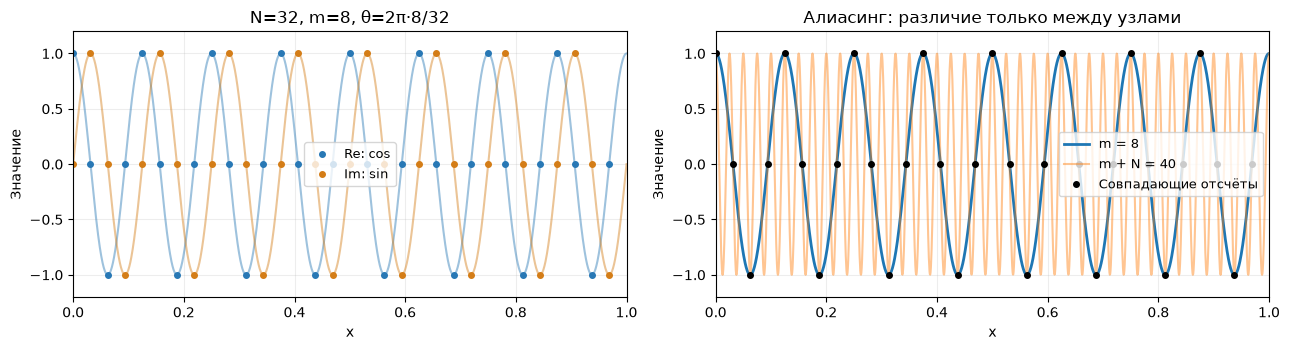

Ошибка совпадения в узлах: 2.06e-14. На сетке есть мода Найквиста m=N/2.


In [4]:
experiment1(N=32, m=8)

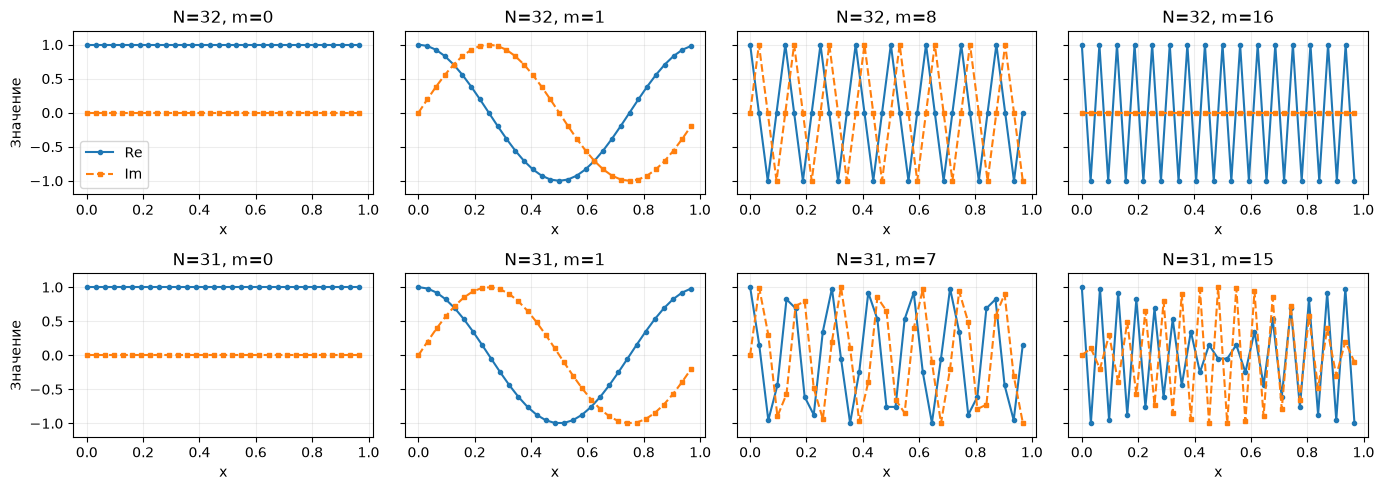

In [5]:
# Сохранённая обзорная панель: особые частоты доступны без виджетов.
fig, axes = plt.subplots(2,4,figsize=(14,5),sharey=True)
for row,N in enumerate([32,31]):
    x=np.arange(N)/N
    for ax,m in zip(axes[row],[0,1,N//4,N//2]):
        ax.plot(x,np.cos(2*np.pi*m*x),'o-',ms=3,label='Re')
        ax.plot(x,np.sin(2*np.pi*m*x),'s--',ms=3,label='Im')
        ax.set(title=f'N={N}, m={m}',xlabel='x',ylim=(-1.2,1.2))
axes[0,0].legend();axes[0,0].set_ylabel('Значение');axes[1,0].set_ylabel('Значение')
fig.tight_layout();plt.show()

**Вопросы:** почему нельзя определить единственную непрерывную функцию по её отсчётам?
Почему синус Найквиста равен нулю в узлах, а косинус — нет?

**Вывод:** дискретные гармоники — базис сеточных векторов. Межузловые линии служат иллюстрацией;
для разностного оператора определяющими являются именно значения в узлах.

## Блок 2. Абсолютная, A- и L-устойчивость · 12–27 минут

### На доске
Для тестового уравнения $y'=\lambda y$ точное решение $y=y_0e^{\lambda t}$ затухает при
$\operatorname{Re}\lambda<0$. Численный метод задаёт $y_{n+1}=R(z)y_n$, $z=\tau\lambda$.
Область абсолютной устойчивости: $\mathcal S=\{z:|R(z)|\le1\}$, исключая полюса.

$$R_{EE}=1+z,\qquad R_{IE}=\frac1{1-z},\qquad R_{CN}=\frac{1+z/2}{1-z/2}.$$

- **A-устойчивость:** вся левая полуплоскость входит в область устойчивости.
- **L-устойчивость:** A-устойчивость и $R(z)\to0$ при $|z|\to\infty$ в левой полуплоскости.
  Для этих рациональных функций предел также можно вычислять по старшим степеням.

EE имеет круг $|1+z|\le1$. IE устойчив вне открытого круга $|1-z|<1$ и A-устойчив.
CN устойчив в замкнутой левой полуплоскости. IE — L-устойчив; CN — нет, поскольку его предел $-1$.
Здесь речь о скалярном тесте и нормальном симметричном операторе диффузии;
мы не обобщаем спектральную картинку на произвольные ненормальные системы.

### Эксперимент 2. Области устойчивости и траектория
Выберите $z=-1$, $-3$, $-4+2i$. На нижних графиках $\tau=1$, $\lambda=z$,
начальное значение 1. Симметричный логарифмический масштаб одинаков для всех методов;
для подробного просмотра малого затухания служит следующий опыт.

In [6]:
panel(experiment2, real=(-4.,0.,.25), imag=(-3.,3.,.25))

interactive(children=(FloatSlider(value=-3.0, description='real', max=0.0, min=-4.0, step=0.25), FloatSlider(v…

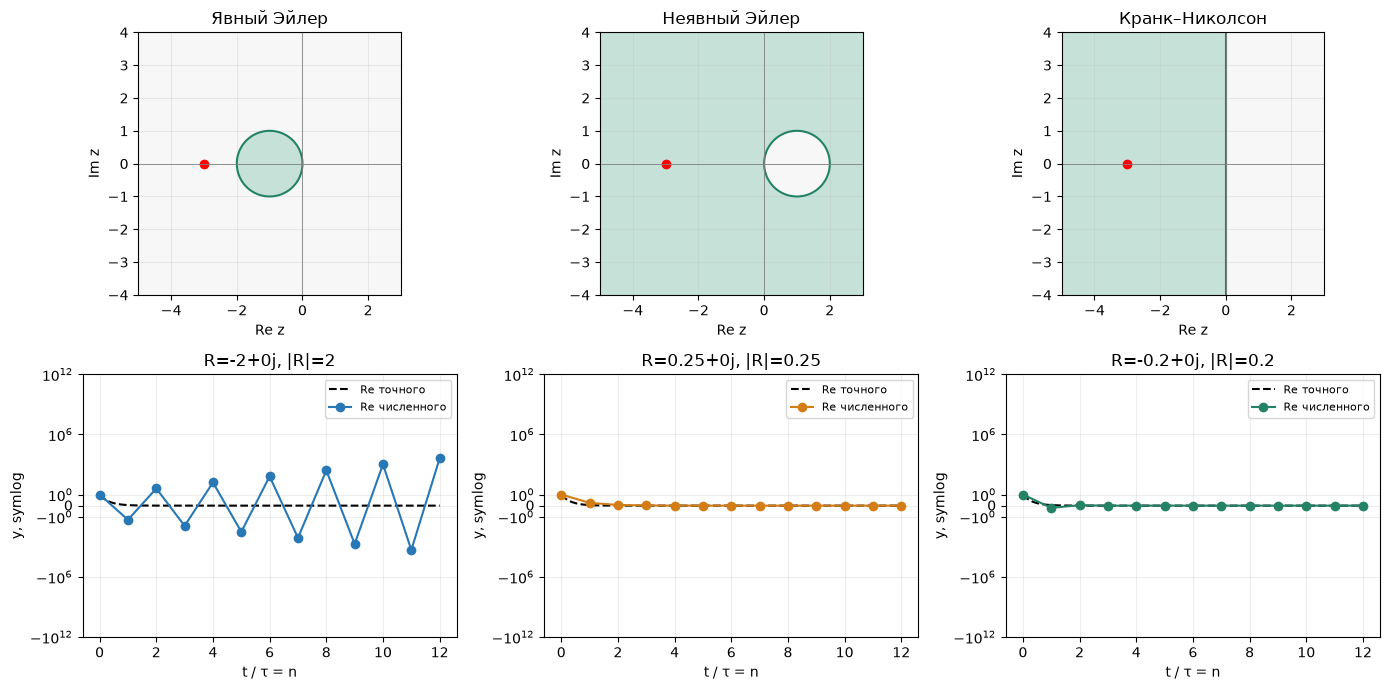

Начальное значение y₀=1; τ=1, λ=z. Зелёный фон: |R(z)|≤1. Для Re z>0 точное решение тоже растёт.


In [7]:
experiment2(real=-3., imag=0.)

### Эксперимент 3. Что происходит с жёсткой затухающей модой?
Пусть $y'=-\mu y$, $a=\mu\tau$. Сравним $e^{-a}$, $(1+a)^{-1}$ и
$(1-a/2)/(1+a/2)$. Увеличьте $a$ от 1 до 30.

In [8]:
panel(experiment3, a=(.1,40.,.1))

interactive(children=(FloatSlider(value=10.0, description='a', max=40.0, min=0.1), Button(description='Обновит…

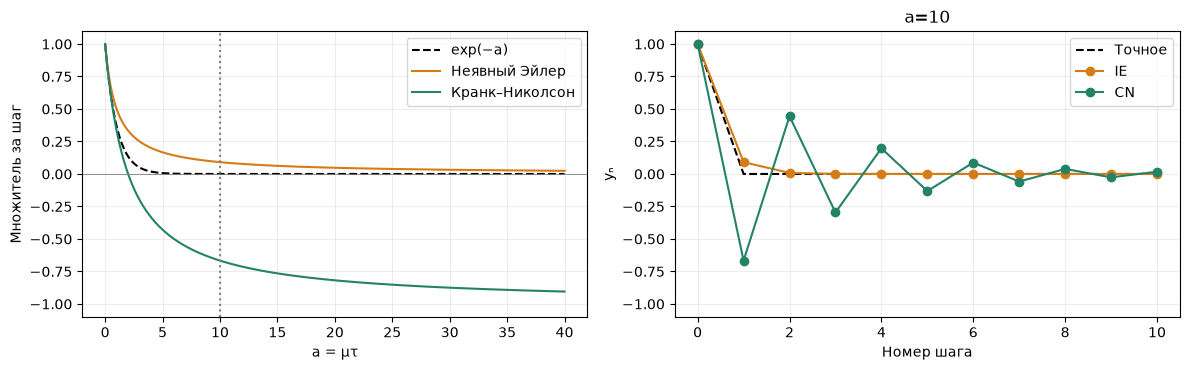

In [9]:
experiment3(a=10.)

**Вопросы:** где EE начинает усиливать решение? Почему при CN последовательность может менять
знак, хотя точное решение положительно? Что дополнительно к A-устойчивости требует L-устойчивость?

**Вывод:** A-устойчивость обеспечивает $|R|\le1$ для затухающих тестовых мод,
но не гарантирует правильную скорость их затухания. При $a\gg1$ CN сохраняет почти незатухающую
знакопеременную составляющую, а IE её подавляет. При конечном шаге IE тоже не совпадает с $e^{-a}$.

## Блок 3. Уравнение диффузии и спектр лапласиана · 27–37 минут

### На доске
Чтобы не путать теплопроводность с собственными значениями, обозначим её $k$:
$$q=-ku_x,\quad \rho c_pu_t=-q_x,\quad u_t=\kappa u_{xx},\quad \kappa=k/(\rho c_p).$$
Непрерывная гармоника $\cos(k_xx)$ затухает как $e^{-\kappa k_x^2t}$.
После центральной разности получаем $\dot U=AU$, $A=\kappa D_{xx}$:
$$ (D_{xx}U)_j=(U_{j+1}-2U_j+U_{j-1})/h^2.$$
Подстановка $e^{ij\theta_m}$ даёт
$$\lambda_m=\frac{\kappa}{h^2}(e^{i\theta_m}-2+e^{-i\theta_m})
=-\frac{4\kappa}{h^2}\sin^2(\pi m/N).$$
Собственные значения неположительны, $\lambda_0=0$. При чётном $N$ максимум модуля
равен $4\kappa/h^2$. Высокая физическая частота соответствует $\min(m,N-m)$, а не просто $m$.

### Эксперимент 4
Показываем $\widehat U_m(t)=e^{\lambda_mt}\widehat U_m(0)$.
**Это точное решение полудискретной системы**, не непрерывного УЧП: оно нужно для отдельного
изучения временной ошибки. Различие $\lambda_m$ и $-\kappa k_x^2$ составляет пространственную ошибку.

In [10]:
panel(experiment4, N=[32,64,128], kappa=(.25,2.,.25))

interactive(children=(Dropdown(description='N', index=1, options=(32, 64, 128), value=64), FloatSlider(value=1…

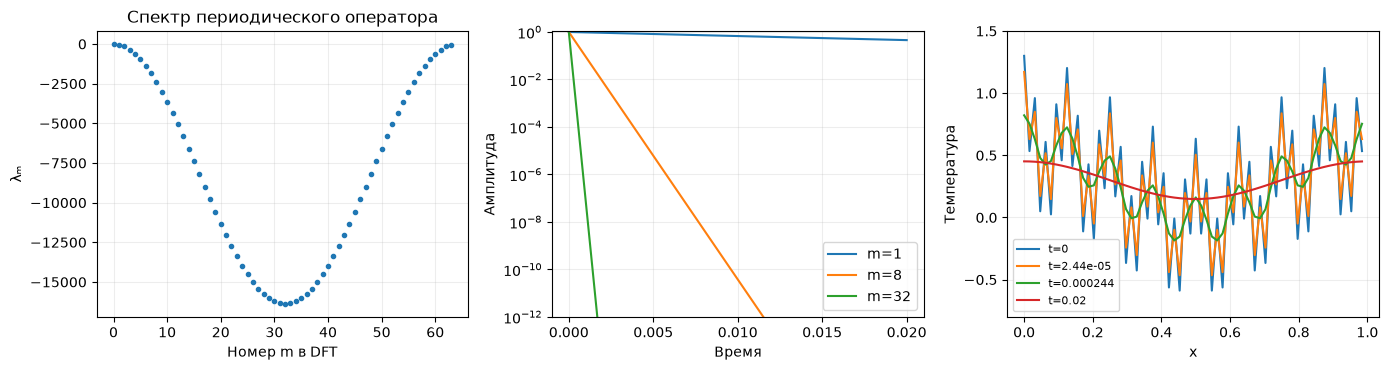

h=0.015625; max |λ|=1.638e+04; мода m=0 не затухает.
m>N/2 соответствует отрицательным частотам m−N; частота не растёт монотонно с индексом DFT.


In [11]:
experiment4(N=64, kappa=1.)

In [12]:
display(decay_animation(N=64))

**Вопросы:** почему средняя температура не меняется? Во сколько раз увеличится жёсткость при
уменьшении $h$ вдвое? Почему спектр симметричен относительно номера $N/2$?

**Вывод:** решение УЧП после пространственной дискретизации — одновременное интегрирование
целого набора ОДУ с разными отрицательными $\lambda_m$. К каждой моде применяется $R(\tau\lambda_m)$.

## Блок 4. Явная схема FTCS · 37–52 минуты

### На доске
$$U_j^{n+1}=rU_{j-1}^n+(1-2r)U_j^n+rU_{j+1}^n,\qquad r=\kappa\tau/h^2,$$
$$G_{EE}(\theta)=1-4r\sin^2(\theta/2).$$
Для чётной периодической сетки $|G|\le1$ эквивалентно $0\le r\le1/2$.
Это также условие выпуклой комбинации и сохранения неотрицательности.
На нечётной фиксированной сетке спектральный предел немного выше:
$r\le[2\cos^2(\pi/(2N))]^{-1}$, но стандартное достаточное условие монотонности остаётся $r\le1/2$.

$$\tau_{\max}=h^2/(2\kappa).$$
Ограничение следует из размещения всего спектра $\tau\lambda_m$ в отрезке $[-2,0]$ устойчивости EE.

### Эксперимент 5
Один локализованный импульс с добавкой $10^{-5}(-1)^j$. Во всех трёх расчётах одинаковое
время $T=30h^2$. История сохраняется полностью; нормы вычисляются на каждом слое:
$$\overline U=h\sum_jU_j,\qquad \|U-\overline U\|_{2,h}=\sqrt{h\sum_j(U_j-\overline U)^2}.$$
Здесь $L=1$, поэтому интеграл равен среднему. Неустойчивый расчёт $r=0.6$ разрешён только в этом опыте.

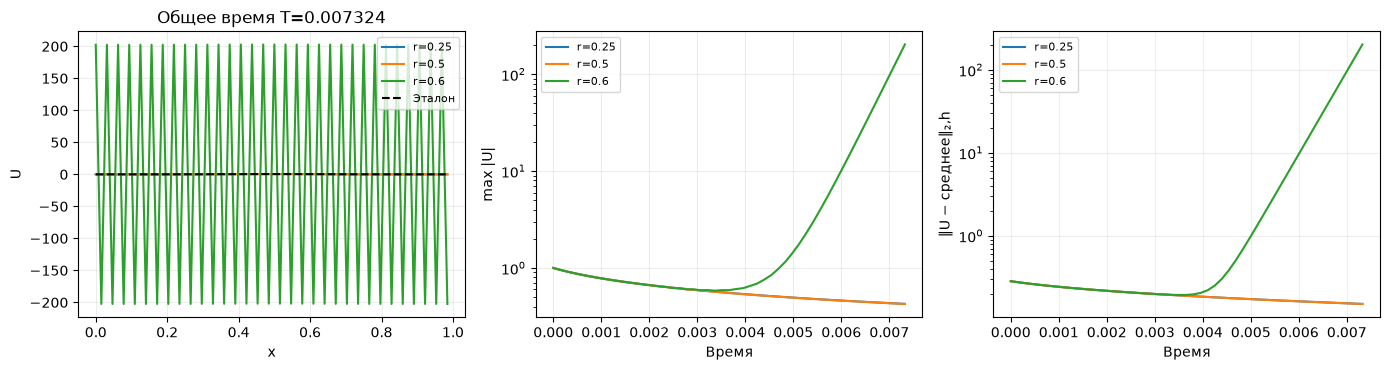

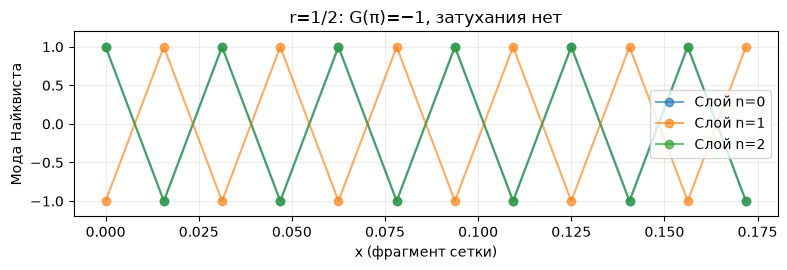

Максимумы при общем T: {0.25: 0.4259606897894041, 0.5: 0.4250844468886742, 0.6: 202.91388280134163}


In [13]:
runs_ftcs = experiment5(N=64)

**Вопросы:** почему $r=1/2$ устойчиво, хотя мода Найквиста не затухает? Может ли сохраняться
среднее при совершенно неверном профиле? Что изменится при уменьшении $h$ вдвое?

**Вывод:** устойчивость означает отсутствие роста, а не обязательное физическое затухание.
На границе $r=1/2$ шахматная мода меняет знак с $G=-1$. Для рабочего расчёта полезен запас по шагу.

## Блок 5. Неявный Эйлер · 52–65 минут

### На доске
$$ (I-\tau A)U^{n+1}=U^n,\qquad
G_{IE}(\theta)=\frac1{1+4r\sin^2(\theta/2)}.$$
При $r\ge0$ имеем $0<G\le1$. Метод A- и L-устойчив, первый порядок по времени.

В каждой внутренней строке матрицы: $[-r,1+2r,-r]$. **На периодической сетке** матрица
циклическая: элементы $-r$ есть также в углах $(0,N-1)$ и $(N-1,0)$.
Обычная прогонка применяется к трёхдиагональной задаче с непериодическими границами;
для периодической нужна её модификация. Здесь используется разреженная LU-факторизация,
переиспользуемая на всех шагах. FFT оставлено для независимого эталона.

### Эксперимент 6
Сравнить EE и IE с малым шагом, IE с десятью шагами и IE с одним шагом до $T=0.01$.
При всех запусках конечное физическое время совпадает; подписи содержат фактические $r$ и число шагов.

EE: 103 шаг., r=0.4; E∞=1.0026e-03
IE: 103 шаг., r=0.4; E∞=1.0062e-03
IE: 10 шаг., r=4.1; E∞=1.0515e-02
IE: 1 шаг., r=41; E∞=1.0386e-01


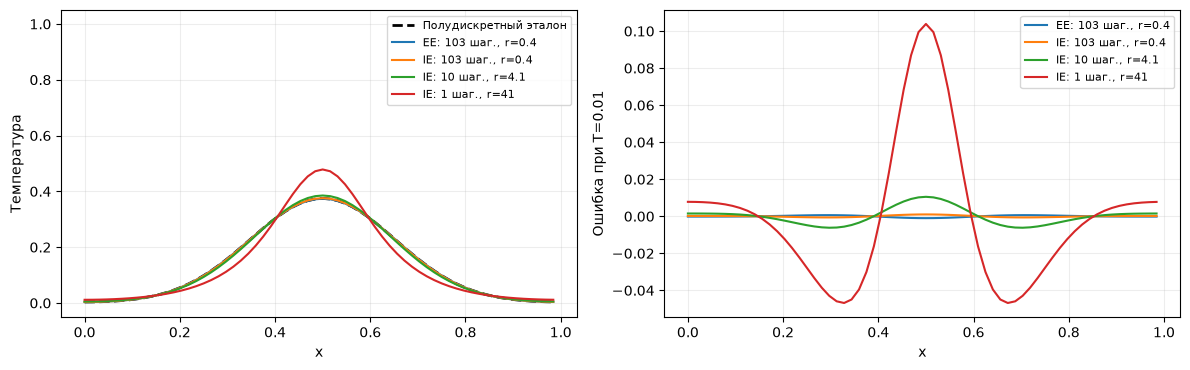

In [14]:
experiment6(N=64)

**Вопросы:** можно ли считать один устойчивый шаг достаточным? Что показывает график ошибки,
если температурные профили на общем масштабе выглядят похожими?

**Вывод:** IE устраняет ограничение устойчивости, но большой шаг меняет скорость затухания.
Сильное подавление мод при $|\tau\lambda|\to\infty$ не означает точность при конечном $\tau$.

## Блок 6. Кранк–Николсон · 65–78 минут

### На доске
Метод трапеций для $\dot U=AU$:
$$\left(I-\frac\tau2A\right)U^{n+1}=\left(I+\frac\tau2A\right)U^n,$$
$$G_{CN}(\theta)=\frac{1-2r\sin^2(\theta/2)}{1+2r\sin^2(\theta/2)}.$$
Разложение $R_{CN}(z)=1+z+z^2/2+O(z^3)$ совпадает с $e^z$ до второго порядка.
CN A-устойчив, но не L-устойчив: при больших отрицательных $z$ получаем $R\to-1$.

### Эксперимент 7
1. Прямоугольный профиль: первые четыре слоя IE, CN и CN со сглаживающим стартом.
2. Гладкий периодический гауссоподобный профиль: сравнение временных ошибок.

**Раннахер:** вместо первого полного шага CN выполняем два полушага IE, затем возвращаемся
к CN. Для моды с $a=-\tau\lambda$ старт даёт $(1+a/2)^{-2}$, подавляя самые быстрые составляющие.
Времена сравнения и начальные данные одинаковы.

In [15]:
panel(experiment7, N=[64,128], r=(2.,40.,2.))

interactive(children=(Dropdown(description='N', index=1, options=(64, 128), value=128), FloatSlider(value=20.0…

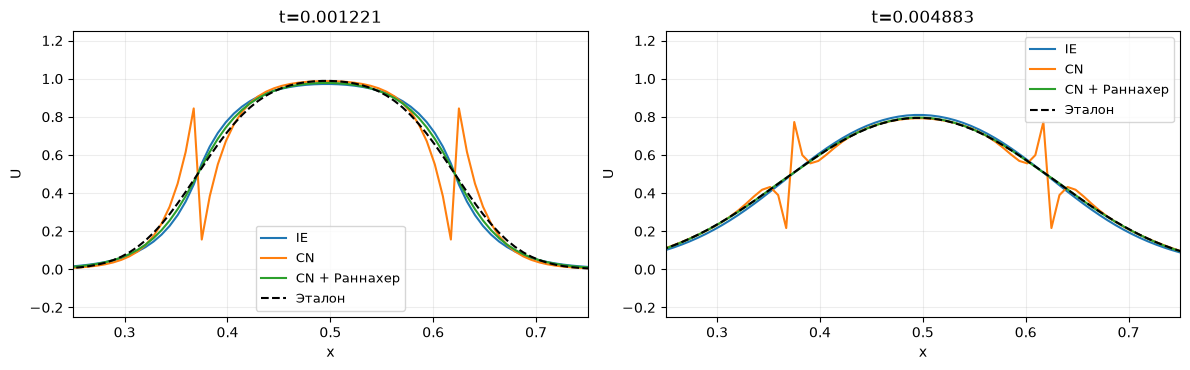

IE временной порядок по двум самым мелким шагам: 1.0009867170424458
CN временной порядок по двум самым мелким шагам: 1.9999866350715718


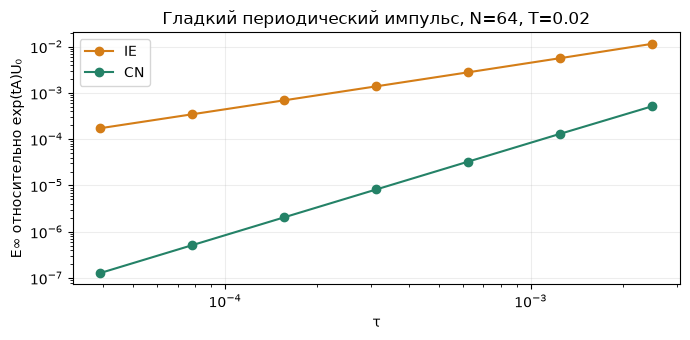

In [16]:
experiment7(N=128, r=20.)

**Вопросы:** почему высокочастотные зубцы не обязаны сопровождаться ростом нормы? Почему
второй порядок проверяется на гладком профиле? Какие моды подавляются стартовыми полушагами?

**Вывод:** второй порядок и A-устойчивость не гарантируют правильного затухания жёстких мод.
Сравнение с $\exp(tA)U_0$ отделяет временную ошибку от пространственной. Не следует переносить
оценку порядка с гладкой задачи на первые слои после разрыва без дополнительного анализа.

## Блок 7. Граничные условия и тепловой баланс · 78–85 минут

### На доске
$$\text{Дирихле: }u=u_D,\quad
\text{Нейман: }-k\partial_nu=q_n,\quad
\text{Робин: }-k\partial_nu=\alpha(u-T_\infty).$$
Здесь $q_n$ — **внешний** поток. В одномерной записи поток $q=-ku_x$ направлен вправо:
на левом конце внешний поток $-q_L$, на правом — $q_R$.
$$\frac{d}{dt}\int\rho c_pu\,dx=q_L-q_R.$$
Тепло $H=\int\rho c_pu$ отличается от квадратичной нормы $\int u^2$.

### Эксперимент 8
Переходим к центрам $N$ ячеек, $x_i=(i+1/2)h$, $\rho c_p=1$, $k=\kappa=0.2$.
Во всех случаях $u_0=1+0.5\sin\pi x$ и IE с одинаковым шагом:

- **Изоляция:** потоки концов равны нулю, предел — среднее начальной температуры.
- **Термостаты:** $u(0)=1$, $u(1)=0$, предел — $1-x$.
- **Теплообмен:** $T_\infty=0$ с обеих сторон, $\alpha=2$, предел — ноль.

Для Робина складываем сопротивления половины граничной ячейки и теплообмена:
$$C_b=\left(h/(2\kappa)+1/\alpha\right)^{-1},\quad
q_L=C_b(T_\infty-U_0),\quad q_R=C_b(U_{N-1}-T_\infty).$$
Для Дирихле $C_b=2\kappa/h$, для изоляции $C_b=0$. Из балансов ячеек
$h\dot U_i=q_{i-1/2}-q_{i+1/2}$ следует точный дискретный баланс.
Накопленные потоки интегрируем по **новым слоям**, согласованно с IE.
Эталон при конечном $T$ вычислен через собственное разложение той же пространственной матрицы;
он не подменяется стационарным пределом.

In [17]:
panel(experiment8, transfer=(.5,5.,.5))

interactive(children=(FloatSlider(value=2.0, description='transfer', max=5.0, min=0.5, step=0.5), Button(descr…

Нейман невязка баланса: 4.907185768843192e-14 ошибка при T: 7.061018436615996e-14
Дирихле невязка баланса: 1.3444800828210646e-13 ошибка при T: 5.6017635530203336e-08
Робин невязка баланса: 1.7763568394002505e-14 ошибка при T: 4.364196306528813e-06


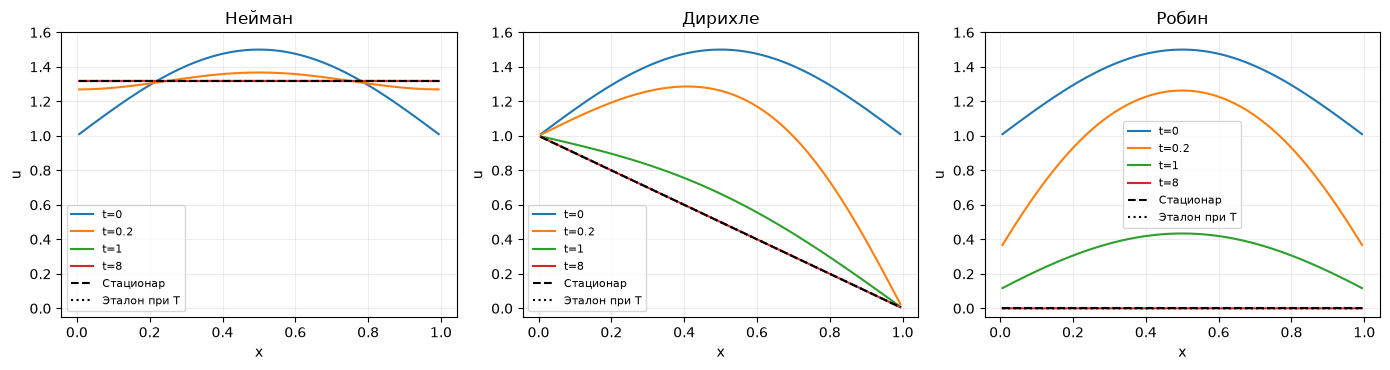

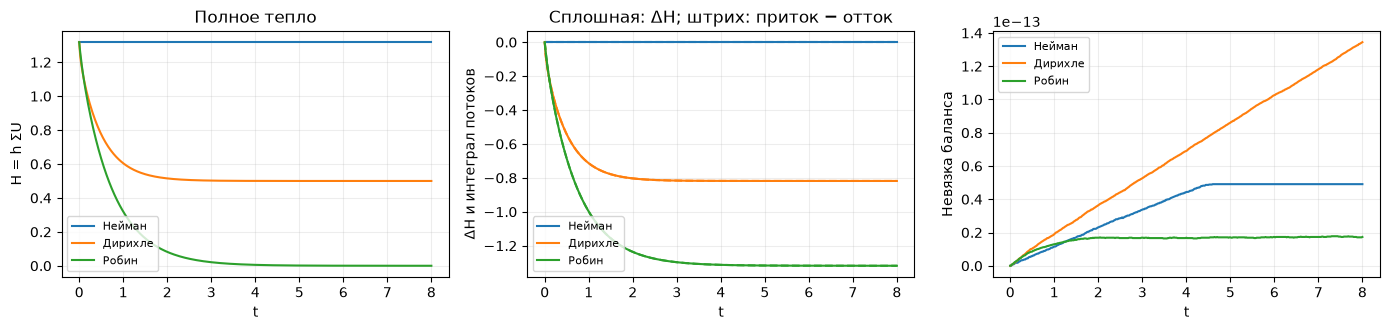

In [18]:
boundary_runs = experiment8(transfer=2.)

**Вопросы:** почему в одном случае тепло сохраняется, а в других нет? Что произойдёт с
Робином при $\alpha\to0$ и $\alpha\to\infty$? Почему в балансе используются те же потоки, что в схеме?

**Вывод:** граничные условия определяют стационар и обмен теплом со средой. Невязка баланса
и ошибка профиля — независимые характеристики; малость одной не доказывает малость другой.

## Блок 8. Итоговое сравнение · 85–90 минут
### Эксперимент 9
Один гладкий периодический профиль, $N=64$, $T=0.02$. Для каждого шага выводятся
$r$, число шагов, максимальная ошибка и дрейф полного тепла.
Неустойчивые варианты EE помечаются и не запускаются; демонстрация их поведения уже была в блоке 4.
Сравнивать эффективность только по числу шагов недостаточно: IE/CN требуют решения системы,
но факторизацию при постоянном шаге можно переиспользовать.

Метод      τ           r     шаги       E∞           дрейф H
EE        0.0025   10.240     8   пропуск: r > 1/2
IE        0.0025   10.240     8   1.1482e-02    1.665e-16
CN        0.0025   10.240     8   5.1500e-04    3.331e-16
EE       0.00125    5.120    16   пропуск: r > 1/2
IE       0.00125    5.120    16   5.6268e-03    6.106e-16
CN       0.00125    5.120    16   1.3077e-04    5.829e-16
EE      0.000625    2.560    32   пропуск: r > 1/2
IE      0.000625    2.560    32   2.7839e-03    1.166e-15
CN      0.000625    2.560    32   3.2772e-05    1.110e-16
EE     0.0003125    1.280    64   пропуск: r > 1/2
IE     0.0003125    1.280    64   1.3845e-03    2.776e-16
CN     0.0003125    1.280    64   8.1979e-06    2.665e-15
EE     0.0001563    0.640   128   пропуск: r > 1/2
IE     0.0001563    0.640   128   6.9036e-04    5.274e-15
CN     0.0001563    0.640   128   2.0498e-06    1.693e-15
EE     7.813e-05    0.320   256   3.4377e-04    5.551e-17
IE     7.813e-05    0.320   256   3.4471e-04  

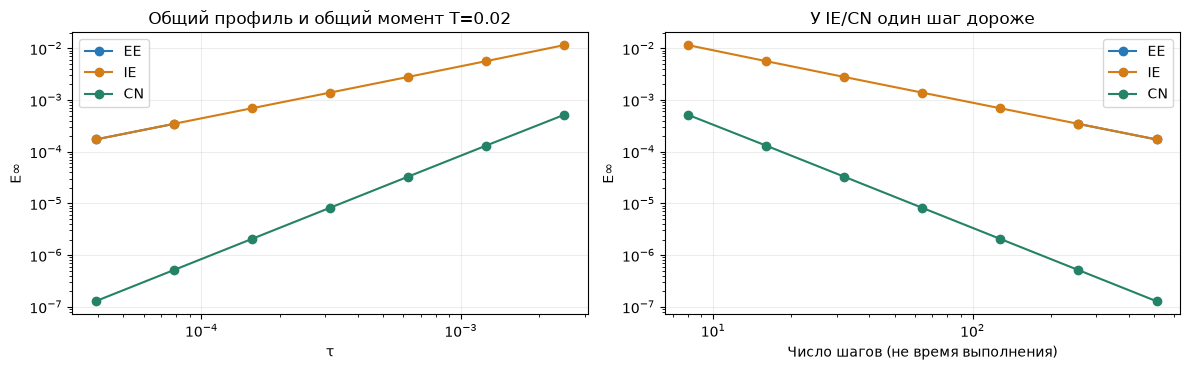

In [19]:
comparison = experiment9(N=64)

| Свойство | Явный Эйлер | Неявный Эйлер | Кранк–Николсон |
|---|---|---|---|
| Порядок по времени на гладком решении | 1 | 1 | 2 |
| A-устойчивость | Нет | Да | Да |
| L-устойчивость | Нет | Да | Нет |
| Линейная система на шаге | Нет | Да | Да |
| Условие устойчивости для чётной периодической сетки | r ≤ 1/2 | Нет ограничения по r | Нет ограничения по r |
| Жёсткие моды | Рост при нарушении ограничения | Подавление при большом −z | Слабо затухающие смены знака |

**Вопрос:** какой метод выбрать для гладкого решения на длинном промежутке времени,
а какой старт — для разрывного профиля? Как проверить, что выбранный шаг достаточно точен?

**Вывод:** выбор метода определяется совместно спектром пространственного оператора,
требуемой точностью, гладкостью данных и стоимостью шага.

Домашняя работа: варианты **7.1–7.3** в [README](../README.md).
Этот маршрут особенно готовит к 7.1; неоднородная теплопроводность и периодический нагрев
подробнее разобраны в [первом ноутбуке](lesson_07_heat.ipynb) и [конспекте](lesson_07_theory.md).

## Проверки воспроизводимости
Служебная ячейка после лекции: независимые проверки спектра, мод, порядка и баланса.

In [20]:
# Спектр и алиасинг на чётных и нечётных сетках.
for N in [15,16,31,32]:
    x,h,lam=grid_spectrum(N);A=periodic_matrix(N)
    for m in [0,1,N//2,N-1]:
        v=np.exp(2j*np.pi*m*x)
        assert np.max(abs(A@v-lam[m]*v)) < 1e-9
        assert np.max(abs(v-np.exp(2j*np.pi*(m+N)*x))) < 1e-12
# Численный шаг должен давать R(tau*lambda) на каждой отдельной моде.
N=32;x,h,lam=grid_spectrum(N);m=7;u0=np.cos(2*np.pi*m*x);tau=.4*h*h
for method in METHODS:
    res=periodic_solve(u0,4*tau,tau,method)
    target=amplification(tau*lam[m],method).real**4*u0
    assert np.max(abs(res['u'][-1]-target)) < 1e-12
    constant=periodic_solve(np.full(N,1.7),.01,.4*h*h,method)
    assert np.max(abs(constant['u']-1.7)) < 1e-12
# Граница EE: реальное численное вычисление шахматной моды.
nyquist=periodic_solve((-1.)**np.arange(N),3*.5*h*h,.5*h*h,'EE')
assert np.max(abs(nyquist['u'][-1]+nyquist['u'][0])) < 1e-12
assert runs_ftcs[.6]['maximum'][-1] > 10*runs_ftcs[.25]['maximum'][-1]
for kind,res in boundary_runs.items():
    assert np.max(abs(res['balance'])) < 1e-9
assert np.ptp(boundary_runs['Нейман']['heat']) < 1e-10
assert abs(amplification(-1e8,'IE')) < 1e-7
assert abs(amplification(-1e8,'CN')+1) < 1e-7
for method,target in [('EE',1),('IE',1),('CN',2)]:
    data=[v for v in comparison if v[0]==method and np.isfinite(v[4])]
    order=np.log2(data[-2][4]/data[-1][4])
    print(f'{method}: измеренный временной порядок {order:.4f}')
    assert abs(order-target)<.15
print('Проверены спектр, алиасинг, усиление мод, сохранение константы, граница EE, порядок и тепловой баланс.')

EE: измеренный временной порядок 0.9990
IE: измеренный временной порядок 1.0010
CN: измеренный временной порядок 2.0000
Проверены спектр, алиасинг, усиление мод, сохранение константы, граница EE, порядок и тепловой баланс.
